# Test-Pipeline: Anonymisierung per Pixelation

Ziel: ein Video einlesen, (Teile davon) pixelieren und als neues Video speichern.
Wir gehen in kleinen Schritten vor.

## Schritt 1: Setup

OpenCV (`cv2`) ist die Bibliothek, mit der wir Videos lesen, Bilder bearbeiten und Videos schreiben.
Installiere sie **im Terminal** (im Projektordner):

```
uv add opencv-python-headless
```

Was passiert dabei?
- `uv add` lädt das Paket herunter, installiert es in `.venv` und trägt es in `pyproject.toml` ein.
- `-headless` heißt: OpenCV ohne eigene Fenster-/GUI-Funktionen. Die brauchen wir nicht (wir zeigen Bilder mit matplotlib an), und es macht die Installation auf fremden Rechnern einfacher.

Wähle danach oben rechts im Notebook als Kernel die `.venv` des Projekts aus (und starte den Kernel ggf. neu).

In [ ]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

print("Python:", sys.executable)  # sollte auf .venv\Scripts\python.exe enden
print("OpenCV Version:", cv2.__version__)

# Pfade relativ zum Projektordner (das Notebook liegt in notebooks/).
PROJECT_ROOT = Path.cwd().parent
INPUT_VIDEO = PROJECT_ROOT / "data" / "raw" / "test.mp4"  # <- Namen an dein Testvideo anpassen
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

print("Video gefunden:", INPUT_VIDEO.exists(), "->", INPUT_VIDEO)

## Schritt 2: Video öffnen und einen Frame anzeigen

Ein Video ist eine Folge von Einzelbildern (**Frames**). Mit `cv2.VideoCapture` öffnen wir es und lesen die Frames nacheinander.

Wichtig zu wissen:
- `cap.read()` liefert zwei Werte: `ok` (hat das Lesen geklappt?) und `frame` (das Bild als NumPy-Array der Form `(Höhe, Breite, 3)`).
- OpenCV speichert Farben in der Reihenfolge **BGR** (Blau, Grün, Rot). matplotlib erwartet **RGB**. Zum Anzeigen müssen wir deshalb die Kanäle umdrehen.
- Das Array hat den Datentyp `uint8`: jeder Wert liegt zwischen 0 und 255.

In [ ]:
cap = cv2.VideoCapture(str(INPUT_VIDEO))
if not cap.isOpened():
    raise RuntimeError(f"Video konnte nicht geöffnet werden: {INPUT_VIDEO}")

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
print(f"Auflösung: {width} x {height}, FPS: {fps:.2f}, Frames: {n_frames}, Dauer: {n_frames / fps:.1f} s")

# Ersten Frame lesen
ok, frame = cap.read()
cap.release()  # Datei wieder freigeben, wenn wir fertig sind

print("Lesen ok:", ok, "| Form:", frame.shape, "| Typ:", frame.dtype)

plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))  # BGR -> RGB
plt.axis("off")
plt.show()

In [ ]:
MODEL_PATH = PROJECT_ROOT / "models" / "face_detection_yunet_2023mar.onnx"
print("Modell gefunden:", MODEL_PATH.exists())

detector = cv2.FaceDetectorYN.create(
    str(MODEL_PATH),
    "",                       # Config-Datei: bei ONNX nicht nötig
    (width, height),          # Bildgröße (Breite, Höhe) - Achtung: Reihenfolge!
    score_threshold=0.5,
    nms_threshold=0.3,        # überlappende Boxen zusammenfassen
    top_k=5000,
)

_, faces = detector.detect(frame)  # faces ist None, wenn nichts gefunden wurde
print("Gefundene Gesichter:", 0 if faces is None else len(faces))

# Zur Kontrolle: Boxen einzeichnen (auf einer Kopie, das Original bleibt unverändert)
preview = frame.copy()
if faces is not None:
    for face in faces:
        x, y, w, h = face[:4].astype(int)
        score = face[-1]
        cv2.rectangle(preview, (x, y), (x + w, y + h), (0, 255, 0), 2)
        print(f"Box: x={x}, y={y}, w={w}, h={h}, Score={score:.2f}")

plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## Schritt 4: Pixelation eines Bildbereichs

Pixelation in drei Teilschritten:
1. Bereich ausschneiden (NumPy-Slicing: `frame[y1:y2, x1:x2]`). Das ist eine *Ansicht* auf das Original, keine Kopie. Wenn wir den Ausschnitt später zurückschreiben, ändert sich das Bild.
2. Den Ausschnitt **stark verkleinern** (z. B. auf 8 × 8 Pixel). Jeder dieser Pixel ist dann der Durchschnitt eines Blocks (`INTER_AREA`).
3. Wieder auf die Originalgröße **vergrößern**, ohne zu glätten (`INTER_NEAREST`). Jeder Pixel wird zu einem sichtbaren Block.

Parameter unserer Funktion:
- `n_blocks`: Anzahl der Blöcke in der Breite. **Kleiner = stärker anonymisiert.** Wir geben bewusst die Blockanzahl statt der Blockgröße in Pixeln vor, damit die Stärke unabhängig von der Gesichtsgröße gleich bleibt.
- `padding`: Rand um die Box (als Anteil). YuNet-Boxen sitzen eng auf dem Gesicht, Haare, Kinn und Ohren würden sonst herausschauen.

Außerdem müssen wir die Box auf die Bildgrenzen zuschneiden (`clip`), sonst gibt es Fehler, wenn ein Gesicht am Rand liegt.

In [15]:
def pixelate_region(frame, box, n_blocks=8, padding=0.3, padding_top=0.6):
    """Pixeliert die Box (x, y, w, h) im Frame und gibt eine Kopie zurück.

    padding:     Rand links/rechts/unten (Anteil von Breite bzw. Höhe)
    padding_top: größerer Rand oben, damit auch Haare/Scheitel bedeckt sind
    """
    x, y, w, h = box
    img_h, img_w = frame.shape[:2]

    # Box vergrößern, danach an den Bildrändern abschneiden
    x1 = max(x - int(w * padding), 0)
    y1 = max(y - int(h * padding_top), 0)
    x2 = min(x + w + int(w * padding), img_w)
    y2 = min(y + h + int(h * padding), img_h)
    if x2 <= x1 or y2 <= y1:  # Box liegt komplett außerhalb des Bildes
        return frame.copy()

    out = frame.copy()
    roi = out[y1:y2, x1:x2]
    roi_h, roi_w = roi.shape[:2]

    # Verkleinern auf n_blocks Blöcke in der Breite (Höhe im gleichen Verhältnis, mind. 1)
    small_w = min(n_blocks, roi_w)
    small_h = max(1, round(roi_h * small_w / roi_w))
    small = cv2.resize(roi, (small_w, small_h), interpolation=cv2.INTER_AREA)

    # Wieder vergrößern, ohne zu glätten -> sichtbare Blöcke
    out[y1:y2, x1:x2] = cv2.resize(small, (roi_w, roi_h), interpolation=cv2.INTER_NEAREST)
    return out

Gefundene Gesichter: 1
Box (x, y, w, h): [180  97  35  43]


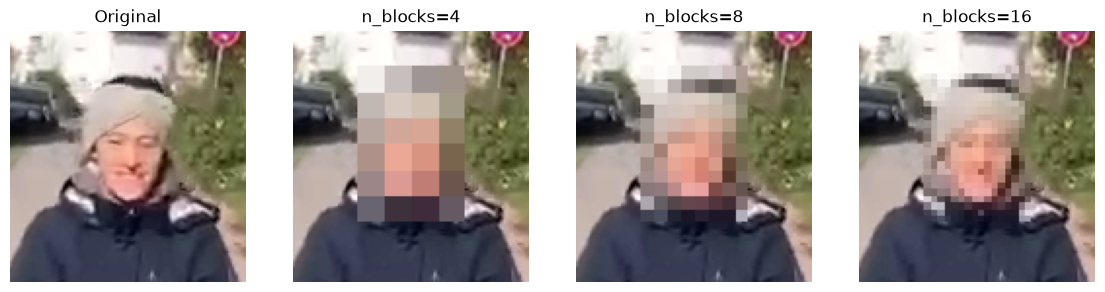

In [16]:
FRAME_INDEX = 200  # <- ändern, falls das Gesicht hier noch zu klein ist oder nicht erkannt wird

# Gezielt einen bestimmten Frame lesen
cap = cv2.VideoCapture(str(INPUT_VIDEO))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_INDEX)
ok, test_frame = cap.read()
cap.release()

_, faces = detector.detect(test_frame)
print("Gefundene Gesichter:", 0 if faces is None else len(faces))

if faces is not None:
    box = faces[0][:4].astype(int)  # erstes Gesicht
    print("Box (x, y, w, h):", box)

    # Ausschnitt um das Gesicht zum Anzeigen (großzügig, damit man Kontext sieht)
    x, y, w, h = box
    m = max(w, h)
    cy1, cy2 = max(y - m, 0), min(y + h + m, height)
    cx1, cx2 = max(x - m, 0), min(x + w + m, width)

    variants = {"Original": test_frame}
    for n in (4, 8, 16):
        variants[f"n_blocks={n}"] = pixelate_region(test_frame, box, n_blocks=n)

    fig, axes = plt.subplots(1, len(variants), figsize=(14, 4))
    for ax, (title, img) in zip(axes, variants.items()):
        ax.imshow(cv2.cvtColor(img[cy1:cy2, cx1:cx2], cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.show()

In [17]:
N_BLOCKS = 8        # Pixelation-Stärke (kleiner = stärker)
HOLD_FRAMES = 15    # so viele Frames wird die letzte Box weiterverwendet, wenn nichts erkannt wird
OUTPUT_VIDEO = OUTPUT_DIR / "test_pixelated.mp4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(INPUT_VIDEO))
writer = cv2.VideoWriter(
    str(OUTPUT_VIDEO),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height),  # Achtung: (Breite, Höhe)
)

detected_frames = 0   # Frames mit frischer Erkennung
held_frames = 0       # Frames, in denen wir die alte Box weiterverwendet haben
unprotected = []      # Frames ohne jede Pixelation
last_boxes, age = [], 0

try:
    for i in range(n_frames):
        ok, frame = cap.read()
        if not ok:
            break

        _, faces = detector.detect(frame)
        if faces is not None:
            last_boxes = [f[:4].astype(int) for f in faces]
            age = 0
            detected_frames += 1
        else:
            age += 1
            if last_boxes and age <= HOLD_FRAMES:
                held_frames += 1
            else:
                last_boxes = []
                unprotected.append(i)

        out = frame
        for box in last_boxes:
            out = pixelate_region(out, box, n_blocks=N_BLOCKS)
        writer.write(out)
finally:
    cap.release()
    writer.release()

print("Gespeichert:", OUTPUT_VIDEO)
print(f"Frames gesamt: {n_frames}")
print(f"  mit Erkennung:      {detected_frames}")
print(f"  mit gehaltener Box: {held_frames}")
print(f"  ohne Schutz:        {len(unprotected)}")
if unprotected:
    print("  erste ungeschützte Frames:", unprotected[:10], "...")

Gespeichert: c:\Users\malin\Masterthesis\master-thesis\data\processed\test_pixelated.mp4
Frames gesamt: 263
  mit Erkennung:      261
  mit gehaltener Box: 2
  ohne Schutz:        0


## Schritt 5: Das ganze Video verarbeiten

Jetzt kombinieren wir alles: Frame für Frame lesen → Gesichter erkennen → pixelieren → in ein neues Video schreiben.

Neu hier:
- `cv2.VideoWriter` schreibt das Ausgabevideo. Wir übernehmen **FPS und Auflösung** vom Original. Codec `mp4v` funktioniert ohne Zusatzsoftware.
- **Lücken überbrücken:** Der Detektor findet nicht in jedem Frame ein Gesicht (klein, gedreht, Bewegungsunschärfe). Ein einzelner verpasster Frame würde das Gesicht aber kurz zeigen. Deshalb merken wir uns die letzte Box und pixelieren sie noch `HOLD_FRAMES` Frames lang weiter, auch wenn nichts erkannt wird.
- Wir zählen, in wie vielen Frames **gar nichts** pixeliert wurde. Das sind die kritischen Frames, die wir uns danach ansehen.
- `try/finally`: Egal was passiert, wird Video und Writer am Ende freigegeben.

## Schritt 3: Gesichter mit YuNet erkennen

**YuNet** ist ein kleines neuronales Netz zur Gesichtserkennung. Es ist in OpenCV eingebaut (`cv2.FaceDetectorYN`), wir brauchen nur die Modelldatei (`.onnx`, ca. 230 KB).

**3a) Modell herunterladen** (einmalig, im **Terminal** im Projektordner, PowerShell):

```powershell
Invoke-WebRequest -Uri "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx" -OutFile "models/face_detection_yunet_2023mar.onnx"
```

Die Datei liegt danach in `models/`. Sie ist klein genug, um sie später mit git ins Repo zu legen. Dann steht sie auch auf dem Klinik-Rechner zur Verfügung, ohne dass dieser Internet braucht.

**3b) Detektor erzeugen und auf den ersten Frame anwenden.** Wichtige Parameter:
- `score_threshold`: Mindest-Sicherheit (0 bis 1). Niedriger = mehr Treffer, aber auch mehr Fehlalarme. Für Anonymisierung ist ein **verpasstes** Gesicht schlimmer als ein Fehlalarm, deshalb wählen wir den Wert eher niedrig.
- `detector.detect(frame)` liefert pro Gesicht eine Zeile mit 15 Zahlen: `x, y, Breite, Höhe` der Box, danach 5 Gesichtspunkte (Augen, Nase, Mundwinkel) und zuletzt den Score.